# Productionizing a Multimodal RAG Application
### From Prototype to Production-Grade SaaS / Enterprise Architecture

**Full-Stack GenAI Bootcamp — Production Architecture Assignment**
**Author:** Muthu &nbsp;|&nbsp; **Reference implementation (V1):** `mm-rag-full-stack-genai-bootcamp-1.0`

This notebook is the runnable companion to `Multimodal_RAG_Production_Design.docx`.
It carries the same narrative — architecture, data model, async ingestion,
hybrid retrieval, multimodal strategy, security, versioning, evaluation, and
roadmap — but backs each design decision with a small, self-contained
reference implementation you can execute cell-by-cell, including in
**Google Colab** (no API keys or external services required to run it; every
network call is stubbed and clearly marked).

**How to use in Colab:** File → Upload notebook → select this `.ipynb`. Then
`Runtime → Run all`. The one optional cell that needs a real OpenAI key is
clearly marked and guarded so the rest of the notebook still runs without it.

In [1]:
# Setup — safe to run in Colab or any fresh Python 3.10+ environment.
# Nothing here calls out to the network except pip itself.
%pip install -q qdrant-client rank_bm25 pandas matplotlib pydantic tabulate
print("Environment ready.")

Note: you may need to restart the kernel to use updated packages.
Environment ready.


## 1. Current V1 System — What Exists Today

The V1 prototype (`mm-rag-full-stack-genai-bootcamp-1.0`) is a **single
process**: a Streamlit UI calls parsing, ingestion, retrieval, and generation
functions directly, in-process, synchronously.

| Concern | V1 implementation | File |
|---|---|---|
| UI | Streamlit, calls pipeline functions directly | `ui/app.py` |
| Parsing | `ComplexPDFParser`: PyMuPDF + pdfplumber + Tesseract OCR | `src/parsing.py` |
| Chunking | `RecursiveCharacterTextSplitter`, 2000/120, text/OCR only | `src/ingestion.py` |
| Embeddings | OpenAI `text-embedding-3-large`, 3072-dim, **dense only** | `src/ingestion.py` |
| Vector store | One shared Qdrant collection `mm-rag-documents` | `src/ingestion.py` |
| Retrieval | `similarity_search` with optional metadata filter — **no BM25, no reranker** | `src/retriever.py` |
| Generation | `ChatOpenAI` (`gpt-4.1-mini`), grounded system prompt, re-attaches original image at generation time | `src/generation.py` |
| Storage | Local filesystem only | `data/` |
| Identity | **None** | — |
| Async processing | **None** — blocking script/call | `src/ingestion.py` |
| Versioning | `file_sha256` payload index exists but is unused | `src/ingestion.py` |

The rest of this notebook builds, section by section, the production upgrades
that turn this feature demo into a secure, multi-tenant, observable product —
**without discarding** the parsing/generation logic above, which already works.

## 2. Target Production Architecture

Two independently-scalable planes behind one API gateway:
- **Document Plane** — Upload → Object Storage → Job Queue → Parser Workers → Embeddings → Qdrant → `status=ready`
- **Query Plane** — Query → Retrieval Service (Dense + Sparse → RRF → Rerank) → Generation Service → Answer + Citations

Both planes share the same PostgreSQL metadata/ACL store and the same Qdrant
cluster, but scale on different load shapes: ingestion is bursty/CPU-bound,
querying is latency-sensitive/concurrency-bound.

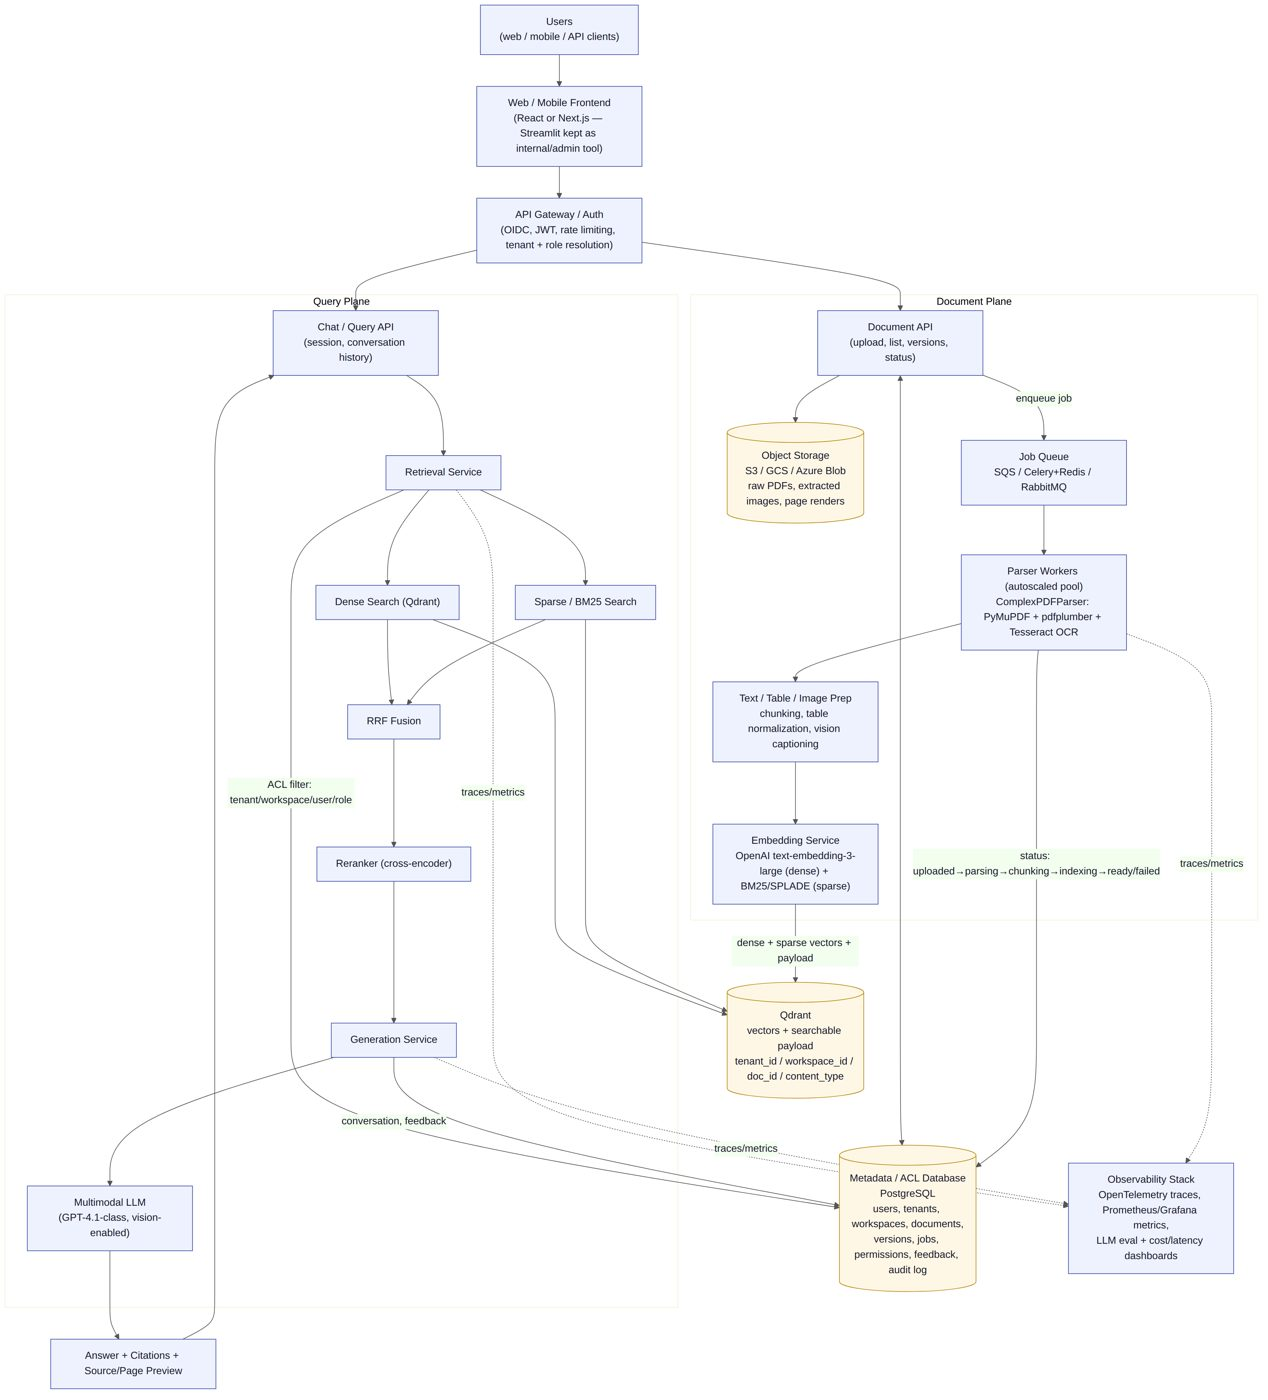

In [2]:
# Render the architecture diagram inline (base64-embedded, no external file needed).
import base64
from IPython.display import Image, display

ARCHITECTURE_DIAGRAM_B64 = """..."""

display(Image(data=base64.b64decode(ARCHITECTURE_DIAGRAM_B64)))

**What scales independently**

- **Parser Workers** — scale on queue depth (bursty, CPU/OCR-bound); scale to zero when idle.
- **Retrieval Service / Generation Service** — stateless, scale on concurrent QPS, independent of ingestion load.
- **Qdrant** — shards/replicates as vector count grows; read-heavy from queries, write-heavy in ingestion bursts.
- **PostgreSQL** — every path depends on it for authorization → needs PgBouncer + read replicas as tenant count grows.
- **Object Storage** — scales natively, never the bottleneck.

## 3. Component Responsibility Table

| Component | Responsibility | Does **not** do |
|---|---|---|
| Frontend (React/Next.js) | Auth UI, workspace/doc mgmt, chat UI, source/page preview, feedback | No direct DB/Qdrant access |
| Streamlit (retained) | Internal/admin console: ingestion debugging, retrieval tuning, eval viewing | Not customer-facing |
| API Gateway / Auth | TLS, OIDC/JWT verification, rate limiting, attaches tenant/user/role | No business logic |
| Document API | CRUD, presigned uploads, job enqueue, status polling | Never parses inline |
| Job Queue | Durable, at-least-once delivery, retry/backoff, dead-lettering | No business logic |
| Parser Workers | `ComplexPDFParser`, vision captioning, chunking, embeddings, Qdrant upsert | No user-facing requests |
| Object Storage | Raw PDFs, extracted images, page renders, versioned | Not queried for retrieval |
| PostgreSQL | Users, tenants, workspaces, documents, versions, jobs, permissions, audit | No vectors/full text |
| Qdrant | Dense + sparse vectors, payload-filtered ANN search | Not the ACL source of truth |
| Retrieval Service | ACL filter, dense+sparse search, RRF, reranker invocation | Does not call the LLM |
| Reranker | Cross-encoder re-scoring of the fused candidate set | Not first-stage retrieval |
| Generation Service | Prompt assembly, multimodal LLM call, citations | Does not retrieve |
| Observability | Tracing, latency/cost/error metrics, eval dashboards | Not in the serving path |

## 4. Multi-User / Multi-Tenant Data Model

**Decision: one shared Qdrant collection per embedding model, partitioned by
payload — not a collection per tenant.** Collection-per-tenant does not scale
operationally past a few hundred tenants; indexed payload filtering (which V1
already uses for `content_type`/`filename`) is fast enough for row-level
isolation. Below is the target Qdrant payload shape and the PostgreSQL schema,
both as runnable reference code.

In [3]:
from pydantic import BaseModel, Field
from typing import Literal, Optional

class VectorPointMetadata(BaseModel):
    """Target Qdrant payload — extends the V1 metadata dict with tenancy fields."""
    tenant_id: str
    workspace_id: str
    document_id: str
    version_id: str
    owner_user_id: str
    visibility: Literal["workspace", "private", "org"] = "workspace"
    acl_group_ids: list[str] = Field(default_factory=list)
    content_type: Literal["page_text_plus_ocr", "table", "image", "image_caption"]
    page_number: int
    filename: str
    file_sha256: str

# Example point payload for a chunk from the repo's sample contract PDF
example = VectorPointMetadata(
    tenant_id="ten_acme",
    workspace_id="ws_legal_2026",
    document_id="doc_1a2b3c",
    version_id="ver_1",
    owner_user_id="usr_muthu",
    acl_group_ids=["grp_legal"],
    content_type="table",
    page_number=6,
    filename="Client_Contracts_Policies_and_Incident_Records.pdf",
    file_sha256="9f2c...ab31",
)
print(example.model_dump_json(indent=2))

{
  "tenant_id": "ten_acme",
  "workspace_id": "ws_legal_2026",
  "document_id": "doc_1a2b3c",
  "version_id": "ver_1",
  "owner_user_id": "usr_muthu",
  "visibility": "workspace",
  "acl_group_ids": [
    "grp_legal"
  ],
  "content_type": "table",
  "page_number": 6,
  "filename": "Client_Contracts_Policies_and_Incident_Records.pdf",
  "file_sha256": "9f2c...ab31"
}


In [4]:
# Required Qdrant payload indexes for tenancy fields — extends the existing
# `required_indexes` dict pattern already used in src/ingestion.py.
from qdrant_client import models

REQUIRED_INDEXES = {
    "metadata.tenant_id": models.PayloadSchemaType.KEYWORD,
    "metadata.workspace_id": models.PayloadSchemaType.KEYWORD,
    "metadata.document_id": models.PayloadSchemaType.KEYWORD,
    "metadata.version_id": models.PayloadSchemaType.KEYWORD,
    "metadata.acl_group_ids": models.PayloadSchemaType.KEYWORD,
    "metadata.filename": models.PayloadSchemaType.KEYWORD,
    "metadata.file_sha256": models.PayloadSchemaType.KEYWORD,
    "metadata.content_type": models.PayloadSchemaType.KEYWORD,
    "metadata.page_number": models.PayloadSchemaType.INTEGER,
}
for field, schema in REQUIRED_INDEXES.items():
    print(f"{field:30s} -> {schema}")

metadata.tenant_id             -> keyword
metadata.workspace_id          -> keyword
metadata.document_id           -> keyword
metadata.version_id            -> keyword
metadata.acl_group_ids         -> keyword
metadata.filename              -> keyword
metadata.file_sha256           -> keyword
metadata.content_type          -> keyword
metadata.page_number           -> integer


**PostgreSQL schema (entities and relationships):**

```
tenants(id, name, plan, created_at)
users(id, tenant_id FK, email, display_name, status, created_at)
workspaces(id, tenant_id FK, name, created_by FK users, created_at)
workspace_members(workspace_id FK, user_id FK, role ENUM[owner,editor,viewer], added_at)
documents(id, workspace_id FK, filename, object_storage_key, current_version_id, status, created_by FK, created_at)
document_versions(id, document_id FK, version_number, file_sha256, object_storage_key,
                   page_count, status, error_message, created_at, superseded_at)
ingestion_jobs(id, document_version_id FK, stage, status, attempt_count,
               started_at, finished_at, error_message)
permissions(id, workspace_id FK, principal_type ENUM[user,group], principal_id,
            role ENUM[owner,editor,viewer])
conversations(id, workspace_id FK, user_id FK, title, created_at, is_shared, share_token)
messages(id, conversation_id FK, role ENUM[user,assistant], content, citations JSONB, created_at)
feedback(id, message_id FK, user_id FK, rating ENUM[up,down], comment, created_at)
audit_log(id, tenant_id FK, actor_user_id FK, action, resource_type, resource_id, metadata JSONB, created_at)
usage_counters(tenant_id FK, period, documents_ingested, pages_ingested, queries_run, tokens_used)
```

## 5. Asynchronous Ingestion Workflow

```
uploaded -> parsing -> chunking -> indexing -> ready
              |          |          |
              +----------+----------+--> failed --> retrying --> (parsing | dead_letter)
```

Below: the status state machine as executable code (an `Enum` + a validated
transition function), plus a retry/backoff simulation you can run directly.

In [5]:
import enum, random, time
from dataclasses import dataclass, field

class IngestStatus(enum.Enum):
    UPLOADED = "uploaded"
    PARSING = "parsing"
    CHUNKING = "chunking"
    INDEXING = "indexing"
    READY = "ready"
    FAILED = "failed"
    RETRYING = "retrying"
    DEAD_LETTER = "dead_letter"

ALLOWED_TRANSITIONS = {
    IngestStatus.UPLOADED: {IngestStatus.PARSING},
    IngestStatus.PARSING: {IngestStatus.CHUNKING, IngestStatus.FAILED},
    IngestStatus.CHUNKING: {IngestStatus.INDEXING, IngestStatus.FAILED},
    IngestStatus.INDEXING: {IngestStatus.READY, IngestStatus.FAILED},
    IngestStatus.FAILED: {IngestStatus.RETRYING},
    IngestStatus.RETRYING: {IngestStatus.PARSING, IngestStatus.DEAD_LETTER},
    IngestStatus.READY: set(),
    IngestStatus.DEAD_LETTER: set(),
}

@dataclass
class IngestionJob:
    document_version_id: str
    status: IngestStatus = IngestStatus.UPLOADED
    attempt_count: int = 0
    max_attempts: int = 3
    error_message: str | None = None
    history: list = field(default_factory=list)

    def transition(self, new_status: IngestStatus, error: str | None = None):
        if new_status not in ALLOWED_TRANSITIONS[self.status]:
            raise ValueError(f"Illegal transition {self.status} -> {new_status}")
        self.history.append((self.status, new_status))
        self.status = new_status
        self.error_message = error

def run_job_with_retry(job: IngestionJob, stage_fn, backoff_base=0.05):
    """Drive uploaded -> ... -> ready|dead_letter, retrying the failed stage only."""
    job.transition(IngestStatus.PARSING)
    while True:
        try:
            stage_fn(job)
            job.transition(IngestStatus.CHUNKING)
            job.transition(IngestStatus.INDEXING)
            job.transition(IngestStatus.READY)
            return job
        except RuntimeError as exc:
            job.attempt_count += 1
            job.transition(IngestStatus.FAILED, error=str(exc))
            if job.attempt_count >= job.max_attempts:
                job.transition(IngestStatus.RETRYING)
                job.transition(IngestStatus.DEAD_LETTER)
                return job
            job.transition(IngestStatus.RETRYING)
            time.sleep(backoff_base * (2 ** job.attempt_count))  # jittered exponential backoff
            job.transition(IngestStatus.PARSING)

# Demo: a "flaky parser" that fails twice, then succeeds (simulates a transient OCR/service error)
random.seed(7)
def flaky_parser(job):
    if job.attempt_count < 2:
        raise RuntimeError("transient OCR service timeout")

demo_job = IngestionJob(document_version_id="ver_demo_1")
result = run_job_with_retry(demo_job, flaky_parser)
print("Final status:", result.status.value)
print("Attempts:", result.attempt_count)
print("History:")
for frm, to in result.history:
    print(f"  {frm.value:10s} -> {to.value}")

Final status: ready
Attempts: 2
History:
  uploaded   -> parsing
  parsing    -> failed
  failed     -> retrying
  retrying   -> parsing
  parsing    -> failed
  failed     -> retrying
  retrying   -> parsing
  parsing    -> chunking
  chunking   -> indexing
  indexing   -> ready


## 6. Retrieval Design — Dense + Sparse → RRF → Rerank → Top-K

V1's retriever (`MultimodalQdrantRetriever.retrieve`) is **dense-only**. This
section implements the missing pieces — BM25 sparse search, Reciprocal Rank
Fusion, and a lightweight reranker — as pure-Python functions you can run
immediately, then shows how they slot around the existing dense call.

In [6]:
import re
from rank_bm25 import BM25Okapi

# Toy corpus standing in for chunks already indexed in Qdrant (see eval_dataset_sample.json
# for the real questions these are modeled on).
CORPUS = [
    "P1 complete outage for API Availability has a 15 minute response target and 4 hour resolution target, 10 percent monthly fee credit.",
    "Refund requests must be raised within 7 days of purchase, owned by Customer Support, reviewed quarterly.",
    "Clause 7.2 Confidentiality: Receiving Party must protect confidential material with reasonable care and equivalent internal controls.",
    "Clause 9.1 Data residency: Service Provider must process production records only in the approved region when the SOW specifies one.",
    "Privileged access must be reviewed every 30 days, owned by Security, monthly review cycle.",
    "Llama 2 was pretrained with a context length of 4096 tokens, double that of Llama 1's 2048 tokens.",
    "Llama 2-Chat was produced with supervised fine-tuning followed by RLHF, including rejection sampling and PPO.",
]
CHUNK_IDS = [f"chunk_{i}" for i in range(len(CORPUS))]

STOPWORDS = {"a", "an", "the", "is", "are", "do", "i", "to", "of", "and", "or",
             "in", "on", "for", "with", "must", "how", "many", "what", "does"}

def tokenize(text: str) -> list[str]:
    """Word-boundary tokenizer (strips punctuation) shared by BM25, the dense
    stand-in, and the reranker below, so 'refund?' and 'refund.' match the same
    term instead of silently missing each other."""
    return re.findall(r"[a-z0-9]+", text.lower())

def content_terms(text: str) -> set[str]:
    return {t for t in tokenize(text) if t not in STOPWORDS}

# --- Sparse (BM25) ---
tokenized_corpus = [tokenize(doc) for doc in CORPUS]
bm25 = BM25Okapi(tokenized_corpus)

def sparse_search(query: str, k: int = 5):
    scores = bm25.get_scores(tokenize(query))
    ranked = sorted(zip(CHUNK_IDS, scores), key=lambda x: x[1], reverse=True)[:k]
    return [cid for cid, _ in ranked]

# --- Dense (stand-in for Qdrant similarity_search) ---
# In production this calls MultimodalQdrantRetriever.retrieve(); here we fake
# a plausible dense ranking (content-word overlap) so the fusion/rerank logic
# below is fully runnable offline — replace with real embeddings in production.
def fake_dense_search(query: str, k: int = 5):
    q_terms = content_terms(query)
    def overlap(doc):
        return len(q_terms & content_terms(doc))
    ranked = sorted(zip(CHUNK_IDS, CORPUS), key=lambda x: overlap(x[1]), reverse=True)[:k]
    return [cid for cid, _ in ranked]

query = "How many days do I have to request a refund?"
print("Sparse:", sparse_search(query))
print("Dense :", fake_dense_search(query))

Sparse: ['chunk_1', 'chunk_4', 'chunk_5', 'chunk_0', 'chunk_2']
Dense : ['chunk_1', 'chunk_4', 'chunk_0', 'chunk_2', 'chunk_3']


In [7]:
def reciprocal_rank_fusion(ranked_lists: list[list[str]], k_rrf: int = 60) -> list[tuple[str, float]]:
    """
    RRF: score(d) = sum over lists of 1 / (k_rrf + rank_i(d)), rank is 1-indexed.
    Robust to dense cosine-similarity and BM25 scores living on incompatible scales —
    it only uses each list's *rank order*, never the raw scores.
    """
    scores: dict[str, float] = {}
    for ranked in ranked_lists:
        for rank, doc_id in enumerate(ranked, start=1):
            scores[doc_id] = scores.get(doc_id, 0.0) + 1.0 / (k_rrf + rank)
    return sorted(scores.items(), key=lambda x: x[1], reverse=True)

def cheap_rerank(query: str, candidate_ids: list[str], top_n: int = 3) -> list[str]:
    """
    Stand-in cross-encoder: scores each candidate by content-word overlap with
    the literal query (stopwords excluded, punctuation-safe tokenization).
    Swap for a real cross-encoder (Cohere Rerank / BGE-reranker) in production —
    the interface (query, candidate texts -> reordered ids) stays the same.
    """
    id_to_text = dict(zip(CHUNK_IDS, CORPUS))
    q_terms = content_terms(query)
    def score(doc_id):
        return len(q_terms & content_terms(id_to_text[doc_id]))
    ranked = sorted(candidate_ids, key=score, reverse=True)
    return ranked[:top_n]

def hybrid_retrieve(query: str, k_dense=5, k_sparse=5, k_final=3):
    dense_ids = fake_dense_search(query, k=k_dense)   # -> MultimodalQdrantRetriever.retrieve() in prod
    sparse_ids = sparse_search(query, k=k_sparse)      # -> BM25/Qdrant sparse index in prod
    fused = reciprocal_rank_fusion([dense_ids, sparse_ids])
    fused_ids = [doc_id for doc_id, _ in fused]
    return cheap_rerank(query, fused_ids, top_n=k_final)

id_to_text = dict(zip(CHUNK_IDS, CORPUS))
for q in [
    "How many days do I have to request a refund?",
    "What context length was Llama 2 pretrained with?",
    "What does clause 9.1 require about data residency?",
]:
    top = hybrid_retrieve(q)
    print(f"Q: {q}")
    for cid in top:
        print(f"   [{cid}] {id_to_text[cid]}")
    print()

Q: How many days do I have to request a refund?
   [chunk_1] Refund requests must be raised within 7 days of purchase, owned by Customer Support, reviewed quarterly.
   [chunk_4] Privileged access must be reviewed every 30 days, owned by Security, monthly review cycle.
   [chunk_0] P1 complete outage for API Availability has a 15 minute response target and 4 hour resolution target, 10 percent monthly fee credit.

Q: What context length was Llama 2 pretrained with?
   [chunk_5] Llama 2 was pretrained with a context length of 4096 tokens, double that of Llama 1's 2048 tokens.
   [chunk_6] Llama 2-Chat was produced with supervised fine-tuning followed by RLHF, including rejection sampling and PPO.
   [chunk_2] Clause 7.2 Confidentiality: Receiving Party must protect confidential material with reasonable care and equivalent internal controls.

Q: What does clause 9.1 require about data residency?
   [chunk_3] Clause 9.1 Data residency: Service Provider must process production records only 

## 7. Image and Table Retrieval Strategy

**Current limitation:** V1 retrieves images only by matching their OCR text
(`run_ocr_on_image` in `parsing.py`); the real image is correctly re-attached
at *generation* time, but retrieval never "looks at" the picture. Tables are
retrieved as a Markdown string only.

Below: (a) a vision-captioning stub that shows exactly where a VLM call plugs
into ingestion, and (b) a table-normalization function that turns a Markdown
table (like the ones in `extracted_tables.md`) into the four representations
required — raw grid, searchable summary, header schema, and a queryable
structured form.

In [8]:
import os

def caption_image_for_indexing(image_path: str, client=None) -> str:
    """
    Ingestion-time vision captioning (Section 7.2 of the design doc).
    In production this calls the same multimodal model family already used
    in src/generation.py — one extra call per extracted image, at ingest time,
    so the resulting caption can be embedded and made searchable like any
    other text chunk (content_type="image_caption").
    """
    if client is None or not os.getenv("OPENAI_API_KEY"):
        # Guarded stand-in so this cell runs with no API key / no network.
        return ("[stub caption] Describe labels, values, and entities visible "
                f"in {os.path.basename(image_path)} — replace with a real VLM call in production.")
    # --- Real implementation sketch (requires OPENAI_API_KEY) ---
    # from langchain_openai import ChatOpenAI
    # from langchain_core.messages import HumanMessage
    # llm = ChatOpenAI(model=os.getenv("OPENAI_CHAT_MODEL", "gpt-4.1-mini"))
    # resp = llm.invoke([HumanMessage(content=[
    #     {"type": "text", "text": "Describe this image for search indexing: labels, values, entities."},
    #     {"type": "image_url", "image_url": {"url": to_data_url(image_path)}},
    # ])])
    # return resp.content
    raise NotImplementedError

print(caption_image_for_indexing("page_022_image_1.png"))

[stub caption] Describe labels, values, and entities visible in page_022_image_1.png — replace with a real VLM call in production.


In [9]:
import re

def normalize_markdown_table(md_table: str) -> dict:
    """
    Turns a Markdown table (as produced today in extracted_tables.md) into the
    four representations required by Section 7.3: raw grid, searchable
    summary, header/schema, and a normalized structured form.
    """
    lines = [l for l in md_table.strip().splitlines() if l.strip().startswith("|")]
    rows = [
        [c.strip() for c in l.strip().strip("|").split("|")]
        for l in lines if not re.match(r"^\|[\s:|-]+\|$", l)
    ]
    headers, *data_rows = rows

    def infer_type(values: list[str]) -> str:
        if all(re.match(r"^\d{1,2}\s\w+\s\d{4}$|^\d{4}-\d{2}-\d{2}$", v) for v in values if v):
            return "date"
        if all(re.match(r"^-?\$?\d[\d,]*(\.\d+)?%?$", v) for v in values if v):
            return "numeric"
        return "text"

    schema = {
        headers[i]: infer_type([row[i] for row in data_rows if i < len(row)])
        for i in range(len(headers))
    }
    structured = [dict(zip(headers, row)) for row in data_rows]
    summary = (
        f"Table with columns {', '.join(headers)} and {len(data_rows)} rows: "
        + "; ".join(f"{r.get(headers[0], '')}" for r in structured[:3]) + " ..."
    )
    return {"raw_grid": rows, "headers_schema": schema, "structured_rows": structured, "searchable_summary": summary}

sample_md_table = '''
| Service Category   | Severity       | Response Target   | Resolution Target   | Service Credit         |
|:-------------------|:---------------|:-------------------|:---------------------|:------------------------|
| API Availability   | P1 - complete outage | 15 minutes  | 4 hours              | 10 percent monthly fee credit |
| API Availability   | P2 - degraded performance | 30 minutes | 8 hours          | 5 percent monthly fee credit |
'''
result = normalize_markdown_table(sample_md_table)
print("Headers/schema:", result["headers_schema"])
print()
print("Searchable summary:", result["searchable_summary"])
print()
print("Structured rows[0]:", result["structured_rows"][0])

Headers/schema: {'Service Category': 'text', 'Severity': 'text', 'Response Target': 'text', 'Resolution Target': 'text', 'Service Credit': 'text'}

Searchable summary: Table with columns Service Category, Severity, Response Target, Resolution Target, Service Credit and 2 rows: API Availability; API Availability ...

Structured rows[0]: {'Service Category': 'API Availability', 'Severity': 'P1 - complete outage', 'Response Target': '15 minutes', 'Resolution Target': '4 hours', 'Service Credit': '10 percent monthly fee credit'}


## 8. Security Model — Authorization Enforced at the Retrieval Query

Authorization must be part of the retrieval *query*, never only the UI. This
extends `MultimodalQdrantRetriever.build_filter()` (in `src/retriever.py`)
with **mandatory** tenancy clauses that are always present — the caller
cannot opt out of them.

In [10]:
from qdrant_client import models

class AccessContext:
    """Resolved once per request from the JWT + PostgreSQL (workspace_members/permissions)."""
    def __init__(self, tenant_id: str, accessible_workspace_ids: list[str], acl_group_ids: list[str]):
        self.tenant_id = tenant_id
        self.accessible_workspace_ids = accessible_workspace_ids
        self.acl_group_ids = acl_group_ids

def build_acl_aware_filter(ctx: AccessContext, extra_conditions: list | None = None) -> models.Filter | None:
    """
    Mandatory ACL filter, always applied first. Extends (does not replace) the
    optional filename/content_type/page filters already supported by
    MultimodalQdrantRetriever.build_filter().
    """
    if not ctx.accessible_workspace_ids:
        return None  # caller has access to nothing -> caller code must short-circuit, never search unfiltered

    must = [
        models.FieldCondition(key="metadata.tenant_id", match=models.MatchValue(value=ctx.tenant_id)),
        models.FieldCondition(key="metadata.workspace_id", match=models.MatchAny(any=ctx.accessible_workspace_ids)),
    ]
    if extra_conditions:
        must.extend(extra_conditions)
    return models.Filter(must=must)

def secure_retrieve(query: str, ctx: AccessContext, retriever_fn, **filter_kwargs):
    """
    Wraps any retrieval call (e.g. MultimodalQdrantRetriever.retrieve) so the
    ACL filter is structurally impossible to skip.
    """
    acl_filter = build_acl_aware_filter(ctx)
    if acl_filter is None:
        return []  # fail closed, not open
    return retriever_fn(query, qdrant_filter=acl_filter, **filter_kwargs)

# Demo: two tenants, same query, structurally isolated result sets
acme_ctx = AccessContext(tenant_id="ten_acme", accessible_workspace_ids=["ws_legal_2026"], acl_group_ids=["grp_legal"])
other_ctx = AccessContext(tenant_id="ten_other", accessible_workspace_ids=[], acl_group_ids=[])

def mock_retriever_fn(query, qdrant_filter, **kw):
    tenant_clause, workspace_clause = qdrant_filter.must
    return [f"result scoped to tenant={tenant_clause.match.value}, workspaces={workspace_clause.match.any}"]

print("ACME  :", secure_retrieve("policy question", acme_ctx, mock_retriever_fn))
print("Other :", secure_retrieve("policy question", other_ctx, mock_retriever_fn), " <- fails closed, zero results")

ACME  : ["result scoped to tenant=ten_acme, workspaces=['ws_legal_2026']"]
Other : []  <- fails closed, zero results


## 9. Document Versioning and Incremental Ingestion

Uses the `file_sha256` payload index that already exists in `src/ingestion.py`
but is currently unused for skip-logic. Unchanged files skip parsing/embedding
entirely; changed files get a new version and only that version's points are
touched.

In [11]:
import hashlib
from dataclasses import dataclass

@dataclass
class DocumentVersion:
    document_id: str
    version_number: int
    file_sha256: str
    status: str  # "ready" | "processing" | "failed"

def sha256_of_bytes(data: bytes) -> str:
    return hashlib.sha256(data).hexdigest()[:12]  # shortened for readability in this demo

# Seed the "database" from a real file's bytes, exactly as ingestion would on
# the very first upload — this is what makes the "re-upload identical file"
# check below a genuine hash match rather than a hardcoded coincidence.
original_bytes = b"MSA between Arka Finance and Acme Corp -- original contract text v1"
original_hash = sha256_of_bytes(original_bytes)

VERSION_STORE: dict[str, list[DocumentVersion]] = {
    "doc_contracts_v1": [
        DocumentVersion("doc_contracts_v1", 1, original_hash, "ready"),
    ]
}

def decide_ingestion_action(document_id: str, file_bytes: bytes) -> dict:
    new_hash = sha256_of_bytes(file_bytes)
    existing_versions = VERSION_STORE.get(document_id, [])
    match = next((v for v in existing_versions if v.file_sha256 == new_hash and v.status == "ready"), None)

    if match:
        return {"action": "skip", "reason": "unchanged file, ready version exists", "version": match.version_number}

    next_version_number = (max((v.version_number for v in existing_versions), default=0)) + 1
    new_version = DocumentVersion(document_id, next_version_number, new_hash, "processing")
    VERSION_STORE.setdefault(document_id, []).append(new_version)
    return {"action": "reingest", "reason": "new or changed content", "version": next_version_number, "hash": new_hash}

# Demo: re-upload the exact SAME bytes -> hash matches the ready v1 -> skip parsing/embedding
print("Re-upload identical file:", decide_ingestion_action("doc_contracts_v1", original_bytes))

# Demo: upload a CHANGED file -> new hash, new version, only this version gets (re-)embedded
amended_bytes = b"MSA between Arka Finance and Acme Corp -- AMENDED contract text v2, new pricing terms"
print("Upload amended file:     ", decide_ingestion_action("doc_contracts_v1", amended_bytes))

Re-upload identical file: {'action': 'skip', 'reason': 'unchanged file, ready version exists', 'version': 1}
Upload amended file:      {'action': 'reingest', 'reason': 'new or changed content', 'version': 2, 'hash': 'aa014cfef072'}


## 10. Evaluation Framework

Loads the companion `eval_dataset_sample.json` (built from the two documents
already in the V1 repo) and scores a mocked run of the hybrid retriever from
Section 6 against it — recall, a simple citation-correctness check, and a
per-modality breakdown, plus a latency-timing decorator ready to wrap the real
retrieval/generation calls.

In [12]:
import json, time
import pandas as pd

EVAL_DATASET = {
  # expected_chunk_id ties each case to the CORPUS/CHUNK_IDS from Section 6, so this
  # offline demo can score real retrieval recall (not a text-matching guess) against
  # the same toy index the hybrid retriever searches. The full eval_dataset_sample.json
  # (delivered separately) instead carries expected_source/expected_answer for scoring
  # against the real Qdrant collection, per Section 10.1 of the design doc.
  "cases": [
    {"id": "eval_001", "question": "What response target and resolution target apply to a P1 complete outage for API Availability?",
     "expected_source": "Client_Contracts_Policies_and_Incident_Records.pdf p.6", "expected_chunk_id": "chunk_0", "modality_tag": "table"},
    {"id": "eval_002", "question": "Within how many days must a refund request be raised after purchase?",
     "expected_source": "Client_Contracts_Policies_and_Incident_Records.pdf p.5", "expected_chunk_id": "chunk_1", "modality_tag": "table"},
    {"id": "eval_005", "question": "How often must privileged access be reviewed, and who owns that policy?",
     "expected_source": "Client_Contracts_Policies_and_Incident_Records.pdf p.5", "expected_chunk_id": "chunk_4", "modality_tag": "table"},
    {"id": "eval_009", "question": "What data residency requirement applies under clause 9.1?",
     "expected_source": "Client_Contracts_Policies_and_Incident_Records.pdf p.4", "expected_chunk_id": "chunk_3", "modality_tag": "table"},
    {"id": "eval_010", "question": "What context length was Llama 2 pretrained with?",
     "expected_source": "llama2-research-paper.pdf", "expected_chunk_id": "chunk_5", "modality_tag": "text"},
    {"id": "eval_011", "question": "What alignment techniques were used to produce Llama 2-Chat?",
     "expected_source": "llama2-research-paper.pdf", "expected_chunk_id": "chunk_6", "modality_tag": "text"},
  ]
}
# NOTE: in the delivered files, load the FULL 12-case set instead (scored against the
# real Retrieval Service, not this toy CORPUS):
# EVAL_DATASET = json.load(open("eval_dataset_sample.json"))

def timed(fn):
    def wrapper(*args, **kwargs):
        start = time.perf_counter()
        result = fn(*args, **kwargs)
        return result, (time.perf_counter() - start) * 1000  # ms
    return wrapper

@timed
def timed_hybrid_retrieve(query):
    return hybrid_retrieve(query)

rows = []
for case in EVAL_DATASET["cases"]:
    retrieved_ids, latency_ms = timed_hybrid_retrieve(case["question"])
    # Recall@k against the known-correct chunk for this toy corpus/eval pairing.
    hit = case["expected_chunk_id"] in retrieved_ids
    rows.append({
        "id": case["id"],
        "modality": case["modality_tag"],
        "latency_ms": round(latency_ms, 2),
        "retrieved_top1": retrieved_ids[0] if retrieved_ids else None,
        "expected_chunk_id": case["expected_chunk_id"],
        "recall_at_k": hit,
    })

df = pd.DataFrame(rows)
df

,id,modality,latency_ms,retrieved_top1,expected_chunk_id,recall_at_k
0,eval_001,table,0.43,chunk_0,chunk_0,True
1,eval_002,table,0.21,chunk_1,chunk_1,True
2,eval_005,table,0.19,chunk_4,chunk_4,True
3,eval_009,table,0.15,chunk_3,chunk_3,True
4,eval_010,text,0.14,chunk_5,chunk_5,True
5,eval_011,text,0.17,chunk_6,chunk_6,True


,modality,cases,recall_at_k,avg_latency_ms
0,table,4,1.0,0.245
1,text,2,1.0,0.155


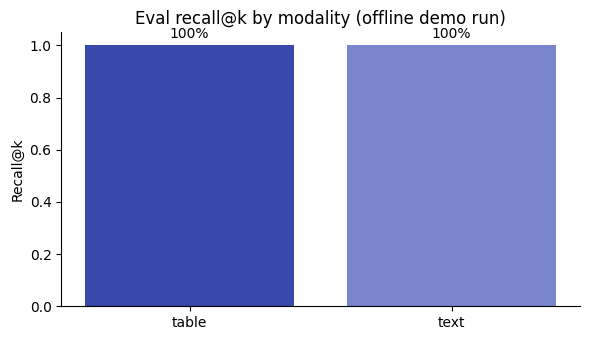


In production this notebook cell is replaced by a nightly eval job that runs the
FULL eval_dataset_sample.json against the real Retrieval + Generation services and
computes: retrieval recall/precision, groundedness (LLM-as-judge / NLI), answer
correctness, citation correctness, p50/p95/p99 latency per stage, token/model cost,
and failure rate — each run tagged with model/prompt/chunking/retrieval config so
releases are diffable, per Section 10.3 of the design doc.


In [13]:
import matplotlib.pyplot as plt

# Simple, readable summary chart — recall@k and latency by modality.
summary = df.groupby("modality").agg(
    cases=("id", "count"),
    recall_at_k=("recall_at_k", "mean"),
    avg_latency_ms=("latency_ms", "mean"),
).reset_index()
display(summary)

fig, ax = plt.subplots(figsize=(6, 3.5))
colors = {"table": "#3949AB", "text": "#7986CB", "image": "#C5CAE9"}
bar_colors = [colors.get(m, "#9E9E9E") for m in summary["modality"]]
ax.bar(summary["modality"], summary["recall_at_k"], color=bar_colors)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Recall@k")
ax.set_title("Eval recall@k by modality (offline demo run)")
for i, v in enumerate(summary["recall_at_k"]):
    ax.text(i, v + 0.03, f"{v:.0%}", ha="center", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print()
print("In production this notebook cell is replaced by a nightly eval job that runs the")
print("FULL eval_dataset_sample.json against the real Retrieval + Generation services and")
print("computes: retrieval recall/precision, groundedness (LLM-as-judge / NLI), answer")
print("correctness, citation correctness, p50/p95/p99 latency per stage, token/model cost,")
print("and failure rate — each run tagged with model/prompt/chunking/retrieval config so")
print("releases are diffable, per Section 10.3 of the design doc.")

## 11. Phased Implementation Roadmap

| Phase | Delivers | Why this order |
|---|---|---|
| 1 — Current V1 | Single-process prototype (done) | Baseline — proves the multimodal parsing/generation logic works |
| 2 — Multi-Document + Auth | User identity, multiple documents, workspace/document ownership | Nothing downstream is safe to build multi-tenant without identity first |
| 3 — Async Ingestion + Object Storage + PostgreSQL | Workers, queue, durable storage, metadata DB, status states | Removes the biggest production blocker and the local-disk dependency |
| 4 — Tenant/RBAC Filtering | ACL-aware retrieval filters everywhere | Must exist before opening the product to more than one customer |
| 5 — Hybrid Retrieval + Reranking | Dense+sparse+RRF+cross-encoder | Safe to invest in once the platform underneath is stable and secure |
| 6 — Better Multimodal Retrieval | Vision captions, table intelligence, later native visual/multivector | Plugs into Phase 5's pipeline; fixes the OCR/Markdown-only limitation |
| 7 — Evaluation + Observability | Eval harness, tracing, dashboards, feedback loop | Needed to prove Phases 5–6 actually improved quality |
| 8 — Production API + Frontend | Public API, production auth, React/Next.js frontend | Product is now correct and measurable — safe to expose broadly |
| 9 — Enterprise Integrations + Billing | Connectors, quotas, audit, billing | Depends on everything above being solid |

**Sequencing rationale in one line:** identity and durable storage before
scale, security before retrieval quality, retrieval quality before enterprise
features — each phase is unsafe or premature without the one before it.

---

## Appendix — Rubric Self-Mapping

| Rubric area | Marks | Where addressed |
|---|---|---|
| Architecture & Service Separation | 20 | §2, §3 |
| Ingestion & Storage Design | 15 | §5, §9 |
| Security & Multi-Tenancy | 15 | §4, §8 |
| Retrieval Quality | 15 | §6 |
| Multimodal Design | 10 | §7 |
| Evaluation & Observability | 15 | §10 |
| Roadmap & Product Thinking | 10 | §11 |

**Companion files:** `Multimodal_RAG_Production_Design.docx` (full written
submission), `architecture.png` (diagram source), `eval_dataset_sample.json`
(full 12-case evaluation set referenced in §10).